In [1]:
import gc
import io
import os
import urllib.request
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import pandas as pd
import polars as pl
import pyarrow.parquet as pq
from dotenv import load_dotenv
import boto3.s3.transfer as s3transfer
from boto3.s3.transfer import TransferConfig

from datetime import datetime
import numpy as np
import scipy.sparse as sp
from implicit.als import AlternatingLeastSquares
import random
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [2]:
plt.style.use("seaborn-v0_8-whitegrid")

In [3]:
load_dotenv()

True

In [4]:
os.environ["POLARS_OOC_MEMORY_BUDGET_MB"] = "2000"
os.environ["POLARS_OOC_LOG_METRICS"] = "1"

# Загрузка конфигурации

Путь до директории с данными:

In [5]:
DATA_DIR = Path(os.getenv("DATA_DIR", "data"))

URL для скачивания файлов с данными:

In [6]:
SOURCE_URLS = {
    "tracks.parquet": os.getenv("TRACKS_URL"),
    "catalog_names.parquet": os.getenv("CATALOG_URL"),
    "interactions.parquet": os.getenv("INTERACTIONS_URL"),
}

Параметры подключения к S3:

In [7]:
S3_ENDPOINT = os.getenv("S3_ENDPOINT")
S3_ACCESS_KEY = os.getenv("S3_ACCESS_KEY")
S3_SECRET_KEY = os.getenv("S3_SECRET_KEY")
S3_BUCKET = os.getenv("S3_BUCKET")
S3_REGION = os.getenv("S3_REGION", "ru-central1")
S3_EDA_PATH = os.getenv("S3_EDA_PATH", "recsys/data")
S3_REC_PATH = os.getenv("S3_REC_PATH", "recsys/recommendations")

# Этап 1. Первичная подготовка данных

Прочитайте файлы с данными, проведите оценку данных на наличие проблем:

* Нужно ли изменить тип идентификаторов?
* Есть ли треки с неизвестными исполнителями, альбомами, жанрами?

При необходимости решите найденные проблемы.

## Пути и загрузка исходных данных

Путь до директории с обработанными файлами:

In [8]:
CLEAN_DIR = DATA_DIR / "clean"

Скачивание файлов с данными, если они не были загружены ранее:

In [9]:
for filename, url in SOURCE_URLS.items():
    target = DATA_DIR / filename
    if target.exists():
        print(f"[ok] {target} уже существует")
        continue
    if not url:
        raise RuntimeError(
            f"Файл {target} отсутствует, а переменная с URL для него не задана в .env"
        )
    print(f"[download] {filename} <- {url}")
    urllib.request.urlretrieve(url, target)
    print(f"[done] {target} ({target.stat().st_size / 1e6:.1f} MB)")

[ok] data/tracks.parquet уже существует
[ok] data/catalog_names.parquet уже существует
[ok] data/interactions.parquet уже существует


## 1. Подготовка директорий

In [10]:
DATA_DIR.mkdir(parents=True, exist_ok=True)

In [11]:
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

## 2. Загрузка треков и каталога

Считываем таблицу треков с метаданными:

In [12]:
tracks = pl.read_parquet(DATA_DIR / "tracks.parquet")

In [13]:
tracks.shape

(1000000, 4)

Считываем каталог треков, артистов, жанров:

In [14]:
catalog = pl.read_parquet(DATA_DIR / "catalog_names.parquet")

In [15]:
catalog.shape

(1812471, 3)

## 3. Метаданные файла взаимодействий

Открываем `interactions.parquet` через `pyarrow.parquet.ParquetFile` (без чтения данных), чтобы оценить объём и типы перед обработкой:

In [16]:
pf = pq.ParquetFile(DATA_DIR / "interactions.parquet")

In [17]:
print("rows:", pf.metadata.num_rows)
print("schema:", pf.schema_arrow)
print("row groups:", pf.metadata.num_row_groups)

rows: 222629898
schema: user_id: int32
track_id: int32
track_seq: int16
started_at: timestamp[ns]
__index_level_0__: int64
-- schema metadata --
pandas: '{"index_columns": ["__index_level_0__"], "column_indexes": [{"na' + 797
row groups: 213


## 4. Приведение типов и ленивый скан взаимодействий

Тип столбца `track.track_id`:

In [18]:
tracks.schema["track_id"]

Int64

Тип столбца `catalog.id`:

In [19]:
catalog.schema["id"]

Int64

Приводим колонки к типу `Int64`:

In [20]:
interactions_lazy = (
    pl.scan_parquet(
        DATA_DIR / "interactions.parquet",
    )
    .with_columns([
        pl.col("user_id").cast(pl.Int64),
        pl.col("track_id").cast(pl.Int64),
    ])
)

## 5. Справочники id по типам из каталога

Для каждого типа (`genre`, `album`, `track`, `artist`) собираем множество валидных id в словарь `catalog_ids`, чтобы в дальнейшем использовать для проверки ссылок:

In [21]:
catalog_ids = {
    t: set(catalog.filter(pl.col("type") == t)["id"].to_list())
    for t in catalog["type"].unique().to_list()
}

In [22]:
{k: len(v) for k, v in catalog_ids.items()}

{'artist': 153581, 'track': 1000000, 'album': 658724, 'genre': 166}

В каталоге 166 жанров, 658 724 альбома, 1 000 000 треков и 153 581 артист. Множества id готовы для проверки ссылок из `tracks`.

## 6. Проверка ссылок треков на каталог

**Что делаем:** объявляем функцию `check_refs`, которая разворачивает список id из колонки (`explode`), отбрасывает null и считает, сколько ссылок указывают на id, отсутствующие в каталоге нужного типа. Возвращает таблицу «битых» ссылок.

In [23]:
def check_refs(tracks_df, col, cat_type) -> pl.DataFrame:
    """
    Проверка, сколько треков ссылаются на id, отсутствующие в каталоге.

    :param tracks_df: Датафрейм с данными о треках.
    :param col: Название колонки в `tracks_df`, содержащей списки идентификаторов для проверки.
    :param cat_type: Ключ в словаре `catalog_ids`, относительно которого выполняется проверка.
    :return: Отфильтрованный датафрейм, содержащий только строки с неизвестными идентификаторами.
    """
    exploded = (
        tracks_df.select(pl.col("track_id"), pl.col(col).alias("ref_id"))
        .explode("ref_id")
        .drop_nulls("ref_id")
    )
    known = catalog_ids.get(cat_type, set())
    unknown = exploded.filter(~pl.col("ref_id").is_in(list(known)))
    n_unknown_tracks = unknown["track_id"].n_unique()
    n_unknown_refs = unknown.height
    print(
        f"{col}: {n_unknown_tracks} треков с неизвестными id, "
        f"{n_unknown_refs} ссылок всего"
    )
    return unknown

### Альбомы

In [24]:
unknown_albums = check_refs(tracks, "albums", "album")
unknown_albums

albums: 0 треков с неизвестными id, 0 ссылок всего


track_id,ref_id
i64,i64


0 треков с неизвестными альбомами, 0 битых ссылок. Таблица пустая — ссылки на альбомы полностью консистентны, фильтрация не требуется.

### Артисты

In [25]:
unknown_artists = check_refs(tracks, "artists", "artist")
unknown_artists

artists: 0 треков с неизвестными id, 0 ссылок всего


track_id,ref_id
i64,i64


0 треков с неизвестными артистами, 0 битых ссылок. Ссылки на артистов консистентны.

### Жанры

In [26]:
unknown_genres = check_refs(tracks, "genres", "genre")

genres: 48345 треков с неизвестными id, 48369 ссылок всего


48 345 треков ссылаются на 48 369 несуществующих жанров. Это единственный тип ссылок с проблемой — невалидные id нужно удалить из списков `genres`.

## 7. Пустые и null-списки в треках

In [27]:
for col in ["albums", "artists", "genres"]:
    n_null = tracks.filter(pl.col(col).is_null()).height
    n_empty = tracks.filter(pl.col(col).list.len() == 0).height
    print(f"{col}: null={n_null}, empty={n_empty}")

albums: null=0, empty=18
artists: null=0, empty=15369
genres: null=0, empty=3687


null-списков нет нигде. 

Пустые списки: 
* albums — 18, 
* artists — 15 369,
* genres — 3 687.

Часть треков не имеет метаданных.

## 8. Базовые статистики взаимодействий

Лениво считаем число строк, число null в `track_id` и `user_id`, минимальную и максимальную дату `started_at`:

In [28]:
stats_basic = pl.scan_parquet(DATA_DIR / "interactions.parquet").select([
    pl.len().alias("n_rows"),
    pl.col("track_id").is_null().sum().alias("n_null_track"),
    pl.col("user_id").is_null().sum().alias("n_null_user"),
    pl.col("started_at").min().alias("min_date"),
    pl.col("started_at").max().alias("max_date"),
]).collect(engine="streaming")
stats_basic

n_rows,n_null_track,n_null_user,min_date,max_date
u32,u32,u32,datetime[ns],datetime[ns]
222629898,0,0,2022-01-01 00:00:00,2022-12-31 00:00:00


222 629 898 строк, null в `track_id` и `user_id` нет. 

Диапазон дат — весь 2022 год. 

Данные покрывают один календарный год без пропусков по краям.

## 9. Уникальные пользователи и треки во взаимодействиях

Лениво считаем число уникальных `user_id` и уникальных `track_id` во взаимодействиях:

In [29]:
n_users = (
    pl.scan_parquet(DATA_DIR / "interactions.parquet")
    .select(pl.col("user_id").unique())
    .collect(engine="streaming")
    .height
)
n_users

1373221

In [30]:
n_tracks = (
    pl.scan_parquet(DATA_DIR / "interactions.parquet")
    .select(pl.col("track_id").unique())
    .collect(engine="streaming")
    .height
)

In [31]:
n_tracks

1000000

1 373 221 уникальный пользователь и 1 000 000 уникальных треков. 

Число треков во взаимодействиях совпадает с числом треков в каталоге — значит, каждый трек каталога хотя бы раз прослушан.

## 10. Проверка: все ли треки из взаимодействий есть в каталоге

Собираем множество `track_id` из `tracks` и проверяем, есть ли во взаимодействиях треки, которых нет в этом множестве:

In [32]:
known_tracks = set(tracks["track_id"].to_list())

In [33]:
unknown_in_interactions = (
    interactions_lazy
    .select(pl.col("track_id").unique())
    .collect()
    .filter(~pl.col("track_id").is_in(list(known_tracks)))
)

In [34]:
unknown_in_interactions

track_id
i64


Во взаимодействиях нет треков, отсутствующих в каталоге. 

Связка interactions - tracks консистентна, джойны безопасны.

## 11. Статистика `track_seq`

Считаем min, max, число null и число уникальных значений в `track_seq`, чтобы понять природу этой колонки:

In [35]:
seq_stats = interactions_lazy.select([
    pl.col("track_seq").min().alias("min_seq"),
    pl.col("track_seq").max().alias("max_seq"),
    pl.col("track_seq").null_count().alias("n_null_seq"),
    pl.col("track_seq").n_unique().alias("n_unique_seq"),
]).collect(engine="streaming")
seq_stats

min_seq,max_seq,n_null_seq,n_unique_seq
i16,i16,u32,u32
1,16637,0,16637


Значения от 1 до 16 637, null нет, 16 637 уникальных значений — непрерывный целочисленный ряд.

## 12. Валидные id по типам из каталога

Выделяем из `catalog` отдельные Series с id для каждого типа (`genre`, `artist`, `album`, `track`) для фильтрации жанров:

In [36]:
valid_genre_ids = catalog.filter(pl.col("type") == "genre")["id"]
valid_artist_ids = catalog.filter(pl.col("type") == "artist")["id"]
valid_album_ids = catalog.filter(pl.col("type") == "album")["id"]
valid_track_ids = catalog.filter(pl.col("type") == "track")["id"]

In [37]:
valid_genres = valid_genre_ids

## 13. Фильтрация невалидных жанров в треках

В каждом списке `genres` оставляем только id, присутствующие в каталоге жанров. Невалидные id будут отброшены:

In [38]:
tracks_clean = (
    tracks
    .with_columns(
        pl.col("genres")
          .list.eval(
              pl.element().filter(pl.element().is_in(valid_genres.implode()))
          )
          .alias("genres")
    )
)

In [39]:
tracks_clean

track_id,albums,artists,genres
i64,list[i64],list[i64],list[i64]
26,"[3, 2490753]",[16],"[11, 21]"
38,"[3, 2490753]",[16],"[11, 21]"
135,"[12, 214, 2490809]",[84],[11]
136,"[12, 214, 2490809]",[84],[11]
138,"[12, 214, … 17294156]",[84],[11]
…,…,…,…
101478482,[21399811],[5540395],"[3, 75]"
101490148,[21403052],[9078726],"[11, 20]"
101493057,[21403883],[11865715],"[44, 75]"


`tracks_clean` сохраняет 1 000 000 строк и 4 колонки, но списки `genres` теперь содержат только валидные id. Структура таблицы не изменилась — можно безопасно джойнить с каталогом по `genre_id`.

## 14. Сколько треков осталось без жанров после фильтрации

Считаем число треков с пустым списком `genres` в `tracks_clean` — оцениваем, как фильтрация повлияла на покрытие жанров.

In [40]:
n_empty_genres = tracks_clean.filter(pl.col("genres").list.len() == 0).height
n_empty_genres

3694

3 694 трека остались без жанров. Прирост небольшой — фильтрация несущественно снизила покрытие жанров, но устранила битые ссылки.

## 15. Флаги наличия артиста и жанра

Добавляем в `tracks_clean` булевы признаки `has_artist` и `has_genre` — True, если соответствующий список непустой. Удобно для фильтрации и анализа покрытия:

In [41]:
tracks_clean = tracks_clean.with_columns([
    (pl.col("artists").list.len() > 0).alias("has_artist"),
    (pl.col("genres").list.len() > 0).alias("has_genre"),
])

### Покрытие метаданных

In [42]:
print(
    "без артистов:", tracks_clean.filter(~pl.col("has_artist")).height,
    "| без жанров:", tracks_clean.filter(~pl.col("has_genre")).height,
)

без артистов: 15369 | без жанров: 3694


15 369 треков без артистов и 3 694 без жанров. Это треки с неполными метаданными: их стоит либо исключать из контентных моделей, либо обрабатывать отдельно.

## 16. Сохранение очищенных таблиц

In [43]:
tracks_clean.write_parquet(CLEAN_DIR / "tracks_clean.parquet")

In [44]:
catalog.write_parquet(CLEAN_DIR / "catalog_names_clean.parquet")

Удаляем исходные данные для очистки оперативной памяти:

In [45]:
del tracks
gc.collect()

0

## 17. Очистка и сохранение взаимодействий

In [46]:
interactions_clean_lazy = (
    pl.scan_parquet(DATA_DIR / "interactions.parquet")
    .select([
        pl.col("user_id").cast(pl.Int64),
        pl.col("track_id").cast(pl.Int64),
        pl.col("track_seq").cast(pl.Int32),
        pl.col("started_at"),
    ])
    .filter(
        pl.col("user_id").is_not_null() &
        pl.col("track_id").is_not_null() &
        pl.col("started_at").is_not_null()
    )
)

In [47]:
interactions_clean_lazy.sink_parquet(
    CLEAN_DIR / "interactions_clean.parquet",
    compression="zstd",
)

Создан `interactions_clean.parquet` — 222 629 898 строк, 4 колонки (`user_id: int64`, `track_id: int64`, `track_seq: int32`, `started_at: timestamp[ns]`). Служебный индекс отброшен, типы согласованы с каталогом, null-строк нет.

## 18. Проверка сохранённого файла взаимодействий

In [48]:
pf_clean = pq.ParquetFile(CLEAN_DIR / "interactions_clean.parquet")

In [49]:
print("rows:", pf_clean.metadata.num_rows)
print("schema:", pf_clean.schema_arrow)

rows: 222629898
schema: user_id: int64
track_id: int64
track_seq: int32
started_at: timestamp[ns]


Число строк совпадает с исходным (222 629 898), схема — ровно 4 колонки с ожидаемыми типами, `__index_level_0__` отсутствует. Файл готов к использованию в моделях и витринах.

## 19. Контрольная проверка: остались ли невалидные жанры

In [50]:
valid_genre_set = set(
    catalog.filter(pl.col("type") == "genre")["id"].to_list()
)

In [51]:
valid_genre_set

{0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 35,
 36,
 37,
 38,
 39,
 40,
 41,
 42,
 43,
 44,
 45,
 46,
 47,
 48,
 49,
 50,
 51,
 52,
 53,
 54,
 55,
 56,
 57,
 58,
 59,
 60,
 61,
 62,
 63,
 64,
 65,
 66,
 67,
 68,
 69,
 70,
 71,
 72,
 73,
 74,
 75,
 76,
 77,
 78,
 79,
 80,
 81,
 82,
 83,
 84,
 85,
 86,
 87,
 88,
 89,
 90,
 91,
 92,
 93,
 94,
 95,
 96,
 97,
 98,
 99,
 100,
 101,
 102,
 103,
 104,
 105,
 106,
 107,
 108,
 109,
 110,
 111,
 112,
 113,
 114,
 115,
 116,
 117,
 118,
 119,
 120,
 121,
 122,
 123,
 127,
 128,
 138,
 190,
 218,
 227,
 246,
 300,
 308,
 310,
 319,
 325,
 332,
 335,
 345,
 383,
 405,
 415,
 432,
 489,
 540,
 597,
 610,
 657,
 702,
 703,
 743,
 762,
 794,
 819,
 849,
 907,
 923,
 1016,
 1058,
 1080,
 1101,
 1182,
 1197,
 1370,
 1484,
 1542}

In [52]:
len(valid_genre_set)

166

Множество содержит 166 id (0–123, затем редкие). Совпадает по мощности с `catalog_ids['genre']` — независимая проверка подтверждает корректность справочника.

Разворачиваем `genres` из `tracks_clean` в плоский вид и фильтруем значения, которых нет в `valid_genre_set`:

In [53]:
bad = (
    tracks_clean.select("track_id", pl.col("genres").alias("g"))
                .explode("g").drop_nulls("g")
                .filter(~pl.col("g").is_in(list(valid_genre_set)))
)

In [54]:
bad

track_id,g
i64,i64


В `tracks_clean` не осталось ни одной ссылки на несуществующий жанр. Фильтрация из раздела 13 подтверждена независимой проверкой; `tracks_clean.parquet` можно использовать как источник метаданных для рекомендательной системы.

Удаляем ненужные объекты для очистки оперативной памяти:

In [55]:
del pf, pf_clean, bad, valid_genre_set, unknown_albums, unknown_artists, unknown_genres
gc.collect()

0

## Заключение

В рамках первого этапа была успешно проведена загрузка, валидация и очистка исходных наборов данных. 

**Основные результаты:**

* Унификация типов данных: Идентификаторы (`user_id`, `track_id`, `id` в каталоге) приведены к типу `Int64`, что гарантирует корректность будущих операций объединения и исключает ошибки сравнения.
* Очистка метаданных треков:
  
    Выявлено и отфильтровано ~48 тыс. невалидных ссылок на жанры.
  
    Ссылки на альбомы и артисты оказались на 100% консистентными.
  
    Добавлены булевы признаки `has_artist` и `has_genre` для удобной фильтрации треков с неполными метаданными.

* Валидация таблицы взаимодействий:
  
    Подтверждена полная целостность: все `track_id` из взаимодействий присутствуют в каталоге треков.
  
    Пропуски в ключевых полях (`user_id`, `track_id`, `started_at`) отсутствуют.
  
    Данные покрывают полный календарный год (2022), содержат ~222.6 млн записей, 1.37 млн уникальных пользователей и 1 млн уникальных треков.

* Оптимизация и сохранение: Служебные индексы удалены, данные сохранены локально.

**Итог**

Сырые данные очищены от битых ссылок и аномалий, схемы таблиц согласованы. Очищенные наборы (`tracks_clean.parquet`, `catalog_names_clean.parquet`, `interactions_clean.parquet`) полностью готовы к проведению разведочного анализа (EDA) и формированию витрин для рекомендательной системы на Этапе 2.

# Этап 2.Анализ данных и их подготовка
Проведите EDA данных, чтобы получить представление:

* о распределении количества прослушанных треков,
* о наиболее популярных треках,
* о наиболее популярных жанрах,
* о треках, которые никто не прослушал.

Сохраните данные в двух файлах в персональном S3-бакете по пути recsys/data/:

* items.parquet — все данные о музыкальных треках,
* events.parquet — все данные о взаимодействиях.

## 1. Настройка подключения к S3

In [56]:
s3 = boto3.client(
    "s3",
    endpoint_url=S3_ENDPOINT,
    aws_access_key_id=S3_ACCESS_KEY,
    aws_secret_access_key=S3_SECRET_KEY,
    region_name=S3_REGION
)

In [57]:
print("S3 bucket:", S3_BUCKET, "| endpoint:", S3_ENDPOINT)

S3 bucket: mle-20261109-edf4b0c3eba4 | endpoint: https://storage.yandexcloud.net


## 2. Распределеие количества прослушиваний по пользователям

In [58]:
user_counts = (
    pl.scan_parquet(CLEAN_DIR/"interactions_clean.parquet")
    .group_by("user_id")
    .agg(pl.len().alias("n_listens"))
    .collect(engine="streaming")
)

In [59]:
user_counts["n_listens"].describe()

statistic,value
str,f64
"""count""",1.373221e6
"""null_count""",0.0
"""mean""",162.12241
"""std""",351.284625
"""min""",1.0
"""25%""",23.0
"""50%""",55.0
"""75%""",154.0
"""max""",16637.0


Распределение сильно скошено вправо: медиана ~55 прослушиваний, среднее ~162, 75-й перцентиль ~154, максимум 16 637. Небольшая доля пользователей даёт непропорционально много прослушиваний (длинный хвост). Это важно для рекомендательной системы — при обучении и оценке стоит учитывать холодный старт и возможные аномалии активности.

## 3. Гистограмма распределения прослушиваний

In [60]:
plt.style.use("seaborn-v0_8-whitegrid")

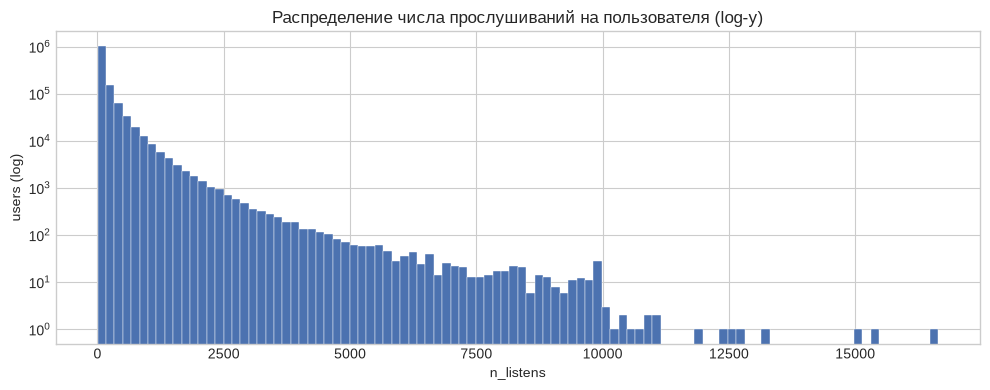

In [61]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(user_counts["n_listens"].to_numpy(), bins=100, log=True, color="#4C72B0", edgecolor="white", linewidth=0.3)
ax.set_title("Распределение числа прослушиваний на пользователя (log-y)")
ax.set_xlabel("n_listens")
ax.set_ylabel("users (log)")
plt.tight_layout()
plt.show()

Гистограмма показывает резкий пик в области малых значений (десятки прослушиваний) и длинный правый хвост. Большинство пользователей имеет менее ~200 прослушиваний, но есть активные пользователи с тысячами. Это ориентир для выбора минимального порога активности при обучении моделей и для анализа холодного старта.

**Квантили:**

In [62]:
qs = [0.5, 0.75, 0.9, 0.95, 0.99, 0.999]
user_counts["n_listens"].quantile(qs)

[55.0, 154.0, 389.0, 650.0, 1576.0, 4061.0]

Типичный пользователь слушает ~55 записей, но распределение крайне неравномерное — небольшая доля сверхактивных пользователей слушает тысячи, поэтому ориентироваться на среднее опасно, лучше на медиану и квантили.

Удаляем ненужные данные для очистки оперативной памяти:

In [63]:
del user_counts
gc.collect()

1812

## 4. Наиболее популярные треки

**Сортировка треков по частоте прослушиваний:**

In [64]:
track_pop = (
    pl.scan_parquet(CLEAN_DIR / "interactions_clean.parquet")
    .group_by("track_id")
    .agg(pl.len().alias("n_listens"))
    .sort("n_listens", descending=True)
    .collect(engine="streaming")
)

In [65]:
track_pop["n_listens"].describe()

statistic,value
str,f64
"""count""",1e6
"""null_count""",0.0
"""mean""",222.629898
"""std""",1369.930708
"""min""",5.0
"""25%""",9.0
"""50%""",19.0
"""75%""",67.0
"""max""",111062.0


Распределение имеет ярко выраженный «длинный хвост»: медиана составляет всего 19 прослушиваний при среднем значении 222.6 и максимуме 111 062 (на 1 млн треков). Из-за сильной асимметрии и экстремальных выбросов использование n_listens в качестве признака может ухудшить качество модели. 

**Список имен треков:**

In [66]:
track_names = (
    catalog.filter(pl.col("type") == "track")
    .select(pl.col("id").alias("track_id"), pl.col("name").alias("track_name"))
)
track_names

track_id,track_name
i64,str
26,"""Complimentary Me"""
38,"""Momma's Boy"""
135,"""Atticus"""
136,"""24 Hours"""
138,"""Don't Upset The Rhythm (Go Bab…"
…,…
101478482,"""На лицо"""
101490148,"""Без капли мысли"""
101493057,"""SKITTLES"""


**Топ-50 самых прослушиваемых треков:**

In [67]:
top_tracks = (
    track_pop.head(50)
    .join(track_names, on="track_id", how="left")
)
top_tracks

track_id,n_listens,track_name
i64,u32,str
53404,111062,"""Smells Like Teen Spirit"""
33311009,106921,"""Believer"""
178529,101924,"""Numb"""
35505245,99490,"""I Got Love"""
65851540,86670,"""Юность"""
…,…,…
76434671,62921,"""Горький вкус"""
84382282,61641,"""Я в моменте"""
39089632,61442,"""Выхода нет"""


**Визуализация Топ-50**

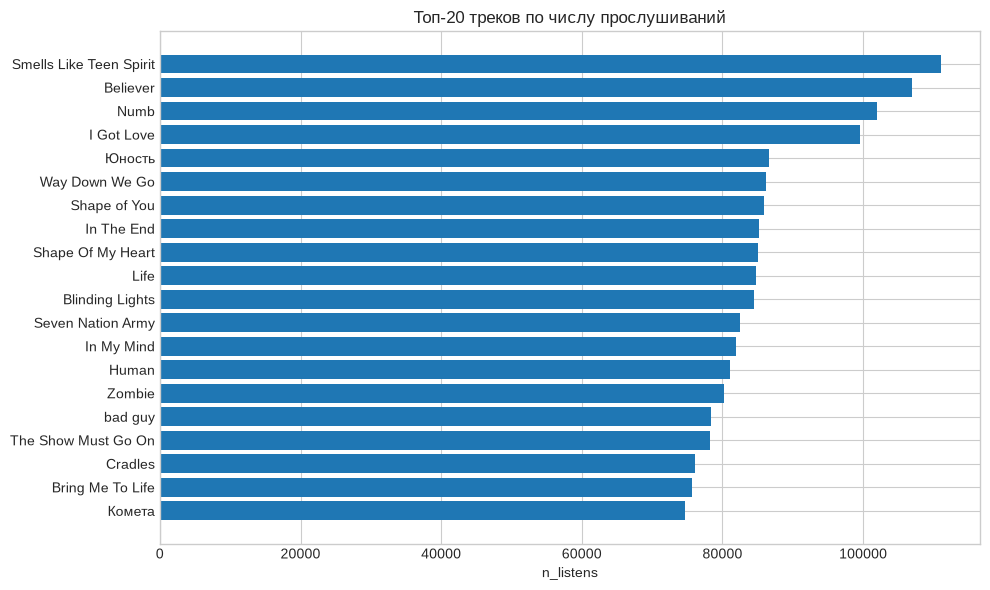

In [68]:
top20 = top_tracks.head(20).to_pandas()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top20["track_name"].fillna(top20["track_id"].astype(str)), top20["n_listens"])
ax.invert_yaxis()
ax.set_title("Топ-20 треков по числу прослушиваний")
ax.set_xlabel("n_listens")
plt.tight_layout()
plt.show()

**Основные наблюдения:**

* Лидер: Трек *Smells Like Teen Spirit* значительно опережает остальные, преодолев отметку в 110 000 прослушиваний.
* Плотность: Начиная с 8-й строчки (*Shape Of My Heart*), значения выравниваются в диапазоне 80 000–85 000.
* Минимум выборки: Замыкает топ-20 трек *Комета* с результатом около ~75 000 прослушиваний.

## 5. Наиболее популярные жанры

**Треки с валидными жанрами:**

In [69]:
track_genres = (
    tracks_clean
    .filter(pl.col("has_genre"))
    .select("track_id", pl.col("genres"))
    .explode("genres")
    .rename({"genres": "genre_id"})
)
track_genres

track_id,genre_id
i64,i64
26,11
26,21
38,11
38,21
135,11
…,…
101493057,75
101495927,3
101495927,75


**Агрегация прослушиваний по жанрам:**

In [70]:
genre_pop = (
    pl.scan_parquet(CLEAN_DIR / "interactions_clean.parquet")
    .join(track_genres.lazy(), on="track_id", how="inner")
    .group_by("genre_id")
    .agg(pl.len().alias("n_listens"))
    .sort("n_listens", descending=True)
    .collect(engine="streaming")
)

In [71]:
genre_pop

genre_id,n_listens
i64,u32
11,55578312
75,37799821
102,31092013
20,26626241
3,25303695
…,…
91,497
82,468
113,388


**Список жанров:**

In [72]:
genre_names = (
    catalog.filter(pl.col("type") == "genre")
    .select(pl.col("id").alias("genre_id"), pl.col("name").alias("genre_name"))
)
genre_names

genre_id,genre_name
i64,str
0,"""all"""
1,"""eastern"""
2,"""rusrock"""
3,"""rusrap"""
4,"""postrock"""
…,…
1182,"""balkan"""
1197,"""experimental"""
1370,"""europop"""


**Топ жанров:**

In [73]:
top_genres = genre_pop.join(genre_names, on="genre_id", how="left")
top_genres.head(10)

genre_id,n_listens,genre_name
i64,u32,str
11,55578312,"""pop"""
75,37799821,"""rap"""
102,31092013,"""allrock"""
20,26626241,"""ruspop"""
3,25303695,"""rusrap"""
68,20120981,"""electronics"""
16,16291557,"""dance"""
2,13166147,"""rusrock"""
14,12772644,"""rock"""


**Визуализация:**

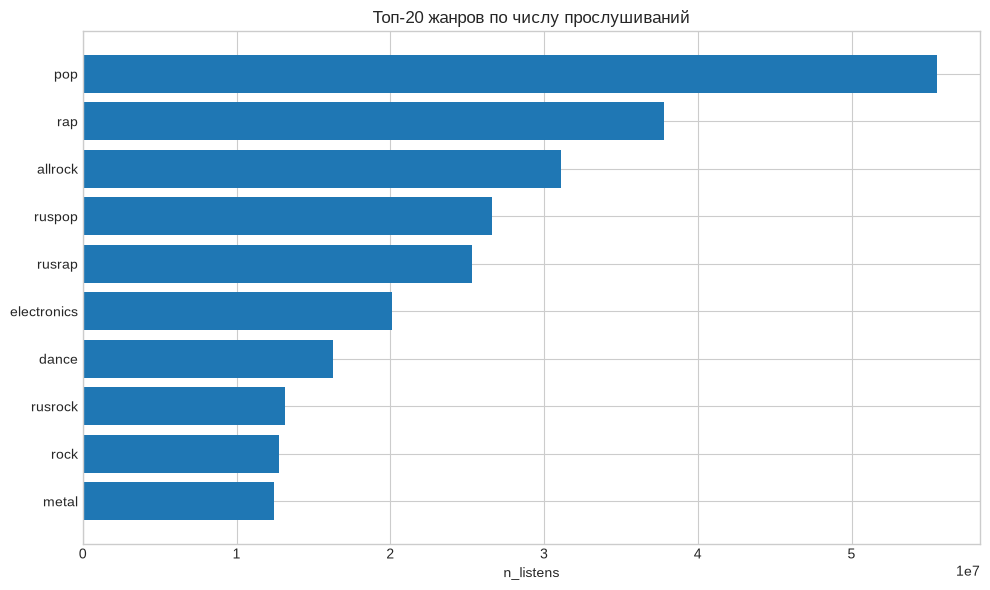

In [74]:
topg = top_genres.head(10).to_pandas()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(topg["genre_name"].fillna(topg["genre_id"].astype(str)), topg["n_listens"])
ax.invert_yaxis()
ax.set_title("Топ-20 жанров по числу прослушиваний")
ax.set_xlabel("n_listens")
plt.tight_layout()
plt.show()

Удаляем использованные данные для очистки оперативной памяти:

In [75]:
del track_pop, track_names, top_tracks, top20
del track_genres, genre_pop, genre_names, top_genres, topg
gc.collect()

17346

## 6. Треки без прослушиваний

Список прослушанных треков:

In [76]:
listened_tracks = set(
    pl.scan_parquet(CLEAN_DIR / "interactions_clean.parquet")
    .select("track_id")
    .unique()
    .collect(engine="streaming")["track_id"].to_list()
)

Список треков без прослушиваний:

In [77]:
unlistened = (
    tracks_clean
    .filter(~pl.col("track_id").is_in(list(listened_tracks)))
    .select("track_id", "genres", "artists", "has_artist", "has_genre")
)

Количество нерослушанных треков:

In [78]:
unlistened.height

0

Все треки были прослушаны хотя бы 1 раз

Вычищаем использованные данные из оперативной памяти:

In [79]:
del listened_tracks, unlistened
gc.collect()

0

## 7. Подготовка данных о музыкальных треках

Формируем витрину: track_id, track_name, artists(names), genres(names), albums(names)

Список всех треков:

In [80]:
catalog_track = catalog.filter(pl.col("type") == "track").select(
    pl.col("id").alias("track_id"), pl.col("name").alias("track_name")
)
catalog_track

track_id,track_name
i64,str
26,"""Complimentary Me"""
38,"""Momma's Boy"""
135,"""Atticus"""
136,"""24 Hours"""
138,"""Don't Upset The Rhythm (Go Bab…"
…,…
101478482,"""На лицо"""
101490148,"""Без капли мысли"""
101493057,"""SKITTLES"""


Список всех исполнителей:

In [81]:
catalog_artist = catalog.filter(pl.col("type") == "artist").select(
    pl.col("id").alias("artist_id"), pl.col("name").alias("artist_name")
)
catalog_artist

artist_id,artist_name
i64,str
4,"""Kenny Dorham"""
5,"""Max Roach"""
7,"""Francis Rossi"""
9,"""Status Quo"""
12,"""Phil Everly"""
…,…
16093680,"""Los Tiburones"""
16097398,"""AMELI"""
16098445,"""2GANGSTA"""


Список всех жанров:

In [82]:
catalog_genre = catalog.filter(pl.col("type") == "genre").select(
    pl.col("id").alias("genre_id"), pl.col("name").alias("genre_name")
)
catalog_genre

genre_id,genre_name
i64,str
0,"""all"""
1,"""eastern"""
2,"""rusrock"""
3,"""rusrap"""
4,"""postrock"""
…,…
1182,"""balkan"""
1197,"""experimental"""
1370,"""europop"""


Список всех альбомов:

In [83]:
catalog_album = catalog.filter(pl.col("type") == "album").select(
    pl.col("id").alias("album_id"), pl.col("name").alias("album_name")
)
catalog_album

album_id,album_name
i64,str
3,"""Taller Children"""
12,"""Wild Young Hearts"""
13,"""Lonesome Crow"""
17,"""Graffiti Soul"""
26,"""Blues Six Pack"""
…,…
21458141,"""The Lazy Singles"""
21458207,"""Jackie Mittoo Anthology"""
21458968,"""Master Composers: Johann Sebas…"


Обогащение данных о треках:

In [84]:
items = (
    tracks_clean
    .join(catalog_track, on="track_id", how="left")
    .with_columns([
        pl.col("artists").alias("artist_ids"),
        pl.col("genres").alias("genre_ids"),
        pl.col("albums").alias("album_ids"),
    ])
)
items

track_id,albums,artists,genres,has_artist,has_genre,track_name,artist_ids,genre_ids,album_ids
i64,list[i64],list[i64],list[i64],bool,bool,str,list[i64],list[i64],list[i64]
26,"[3, 2490753]",[16],"[11, 21]",true,true,"""Complimentary Me""",[16],"[11, 21]","[3, 2490753]"
38,"[3, 2490753]",[16],"[11, 21]",true,true,"""Momma's Boy""",[16],"[11, 21]","[3, 2490753]"
135,"[12, 214, 2490809]",[84],[11],true,true,"""Atticus""",[84],[11],"[12, 214, 2490809]"
136,"[12, 214, 2490809]",[84],[11],true,true,"""24 Hours""",[84],[11],"[12, 214, 2490809]"
138,"[12, 214, … 17294156]",[84],[11],true,true,"""Don't Upset The Rhythm (Go Bab…",[84],[11],"[12, 214, … 17294156]"
…,…,…,…,…,…,…,…,…,…
101478482,[21399811],[5540395],"[3, 75]",true,true,"""На лицо""",[5540395],"[3, 75]",[21399811]
101490148,[21403052],[9078726],"[11, 20]",true,true,"""Без капли мысли""",[9078726],"[11, 20]",[21403052]
101493057,[21403883],[11865715],"[44, 75]",true,true,"""SKITTLES""",[11865715],"[44, 75]",[21403883]


Таблица соответствий треков и исполнителей:

In [85]:
items_artists = (
    items.select("track_id", pl.col("artist_ids"))
    .explode("artist_ids")
    .rename({"artist_ids": "artist_id"})
    .join(catalog_artist, on="artist_id", how="left")
    .group_by("track_id")
    .agg(pl.col("artist_name").drop_nulls().alias("artist_names"))
)
items_artists

track_id,artist_names
i64,list[str]
633522,"[""Joe Dassin""]"
51822994,"[""Фактор 2""]"
28813226,"[""ILWT""]"
77280669,"[""LAY""]"
4071353,"[""Красная плесень""]"
…,…
33225728,"[""Сергей Пенкин""]"
3718455,"[""Norah Jones""]"
43574618,"[""Cloves""]"


Таблица соответствия треков и жанров:

In [86]:
items_genres = (
    items.select("track_id", pl.col("genre_ids"))
    .explode("genre_ids")
    .rename({"genre_ids": "genre_id"})
    .join(catalog_genre, on="genre_id", how="left")
    .group_by("track_id")
    .agg(pl.col("genre_name").drop_nulls().alias("genre_names"))
)
items_genres

track_id,genre_names
i64,list[str]
14180890,"[""folk"", ""celtic""]"
72112981,"[""pop"", ""ruspop""]"
26667311,"[""forchildren""]"
83199068,"[""electronics"", ""house""]"
89302008,"[""pop""]"
…,…
216017,"[""rock"", ""allrock""]"
94513596,"[""dance""]"
10876,"[""pop""]"


In [87]:
items_albums = (
    items.select("track_id", pl.col("album_ids"))
    .explode("album_ids")
    .rename({"album_ids": "album_id"})
    .join(catalog_album, on="album_id", how="left")
    .group_by("track_id")
    .agg(pl.col("album_name").drop_nulls().alias("album_names"))
)
items_albums

track_id,album_names
i64,list[str]
255612,"[""Ignition"", ""The Complete John Waite, Volume One: Falling Backwards"", … ""Classic 80s Movie Songs""]"
20009491,"[""Царапины""]"
96344812,"[""Tricky""]"
1616613,"[""The Rocky Horror Picture Show - Original Soundtrack""]"
63355647,"[""Весна у окна"", ""Весна у окна""]"
…,…
88900360,"[""Нохчийчоь""]"
4890705,"[""Worldwide 001"", ""Brave New World"", … ""Decade of Viper (For Yt Fingerpint Only)""]"
62344081,"[""ALT F4""]"


Итоговая таблица с трекам:

In [88]:
items_final = (
    items
    .drop(["artists", "genres", "albums"])
    .join(items_artists, on="track_id", how="left")
    .join(items_genres, on="track_id", how="left")
    .join(items_albums, on="track_id", how="left")
    .with_columns([
        pl.col("artist_names").fill_null([]),
        pl.col("genre_names").fill_null([]),
        pl.col("album_names").fill_null([]),
    ])
)
items_final

track_id,has_artist,has_genre,track_name,artist_ids,genre_ids,album_ids,artist_names,genre_names,album_names
i64,bool,bool,str,list[i64],list[i64],list[i64],list[str],list[str],list[str]
26,true,true,"""Complimentary Me""",[16],"[11, 21]","[3, 2490753]","[""Elizabeth & the Catapult""]","[""pop"", ""folk""]","[""Taller Children"", ""Taller Children""]"
38,true,true,"""Momma's Boy""",[16],"[11, 21]","[3, 2490753]","[""Elizabeth & the Catapult""]","[""pop"", ""folk""]","[""Taller Children"", ""Taller Children""]"
135,true,true,"""Atticus""",[84],[11],"[12, 214, 2490809]","[""Noisettes""]","[""pop""]","[""Wild Young Hearts"", ""Wild Young Hearts"", ""Wild Young Hearts""]"
136,true,true,"""24 Hours""",[84],[11],"[12, 214, 2490809]","[""Noisettes""]","[""pop""]","[""Wild Young Hearts"", ""Wild Young Hearts"", ""Wild Young Hearts""]"
138,true,true,"""Don't Upset The Rhythm (Go Bab…",[84],[11],"[12, 214, … 17294156]","[""Noisettes""]","[""pop""]","[""Wild Young Hearts"", ""Wild Young Hearts"", … ""2000s Indie Nostalgia""]"
…,…,…,…,…,…,…,…,…,…
101478482,true,true,"""На лицо""",[5540395],"[3, 75]",[21399811],"[""FLESH""]","[""rusrap"", ""rap""]","[""На лицо""]"
101490148,true,true,"""Без капли мысли""",[9078726],"[11, 20]",[21403052],"[""Даня Милохин""]","[""pop"", ""ruspop""]","[""Без капли мысли""]"
101493057,true,true,"""SKITTLES""",[11865715],"[44, 75]",[21403883],"[""WhyBaby?""]","[""foreignrap"", ""rap""]","[""SKITTLES""]"


Записываем данные в файл:

In [89]:
STEP2_OUT_DIR = DATA_DIR / "step2_out"

In [90]:
STEP2_OUT_DIR.mkdir(parents=True, exist_ok=True)

In [91]:
items_final.write_parquet(STEP2_OUT_DIR / "items.parquet")

Удаляем промежуточные данные из оперативной памяти:

In [92]:
del catalog_track, catalog_artist, catalog_genre, catalog_album
del items, items_artists, items_genres, items_albums
gc.collect()

0

## 8. Подготовка данных о взаимодействиях

Получение данных о взаимодействиях:

In [93]:
events_lazy = (
    pl.scan_parquet(CLEAN_DIR / "interactions_clean.parquet")
    .select([
        pl.col("user_id").cast(pl.Int64),
        pl.col("track_id").cast(pl.Int64),
        pl.col("track_seq").cast(pl.Int32),
        pl.col("started_at"),
    ])
    .with_columns(pl.lit(1, dtype=pl.Int8).alias("listened"))
)

In [94]:
STEP2_OUT_DIR = DATA_DIR / "step2_out"

In [95]:
STEP2_OUT_DIR.mkdir(parents=True, exist_ok=True)

Сохранение данных о взаимодействиях в локальный файл:

In [96]:
events_lazy.sink_parquet(STEP2_OUT_DIR / "events.parquet", compression="zstd")

Проверка записанного файла:

In [97]:
pf_ev = pq.ParquetFile(STEP2_OUT_DIR / "events.parquet")

In [98]:
pf_ev.metadata.num_rows

222629898

In [99]:
pf_ev.schema_arrow

user_id: int64
track_id: int64
track_seq: int32
started_at: timestamp[ns]
listened: int8

## Выгрузка данных в S3

Размер части multipart-загрузки:

In [100]:
CHUNK_MB = 32

In [101]:
def upload_file(local_path: Path, s3_key: str):
    """
    Загрузка данных в S3.

    :param local_path: Путь к локальному файлу.
    :param s3_key: Ключ объекта в S3.
    """
    cfg = TransferConfig(
        multipart_threshold=CHUNK_MB * 1024**2,
        multipart_chunksize=CHUNK_MB * 1024**2,
        max_concurrency=4
    )
    transfer = s3transfer.S3Transfer(s3, cfg)
    transfer.upload_file(str(local_path), S3_BUCKET, s3_key)
    print(f"uploaded {local_path.name} -> s3://{S3_BUCKET}/{s3_key}")


Данные загружены в S3:

![](./docs/step2_s3.jpg)

## Заключение

В рамках второго этапа был проведен разведочный анализ данных и выполнена финальная подготовка витрин для построения рекомендательной системы. 

**Основные результаты:**

* Выявлена сильная правосторонняя асимметрия как в активности пользователей (медиана ~55 прослушиваний, максимум >16 000), так и в популярности треков (медиана ~19 прослушиваний, максимум >111 000).
  
* Определены доминирующие жанры в выборке (pop, rap, allrock, ruspop, rusrap, electronics).
  
* Выяслено, что в каталоге нет треков без прослушиваний. Все 1 000 000 треков были прослушаны хотя бы один раз, что исключает проблему cold-start для исторических треков.
  
* Сформирована единая таблица items, содержащая `track_id`, название трека, а также агрегированные списки текстовых названий исполнителей, жанров и альбомов (`artist_names`, `genre_names`, `album_names`). Сохранены булевы флаги наличия метаданных (`has_artist`, `has_genre`).
  
* Подготовлена таблица взаимодействий items.

* Обе итоговые таблицы (`items.parquet` и `events.parquet`) успешно сохранены локально и выгружены в персональный S3-бакет по пути `recsys/data/` с использованием multipart-загрузки.

**Итог:** 

Данные трансформированы из сырых логов в две оптимизированные, обогащенные метаданными таблицы. Схемы согласованы, аномалии проанализированы и учтены. Витрины `items` и `events` полностью готовы к загрузке в распределенные вычислительные среды  и непосредственному обучению рекомендательных моделей на следующем этапе.

# Этап 3. Офлайн-рекомендации

Подготовьте данные для обучения:

* Загрузите ранее сохранённые данные из файлов `items.parquet`, `events.parquet`.
* Разбейте данные на тренировочную и тестовую выборки: в тренировочную отнесите все данные до 16 декабря 2022 года (не включительно).

Рассчитайте рекомендации нескольких типов, сохраните каждый тип в своём файле, в персональном S3-бакете по пути `recsys/recommendations/`:

* топ популярных — в `top_popular.parquet`;
* персональные (при помощи ALS) — в `personal_als.parquet`;
* похожие треки, или i2i (при помощи ALS) — в `similar.parquet`.

Постройте ранжирующую модель, которая использует минимум три признака. Отранжируйте рекомендации, а итоговые сохраните в `recommendations.parquet`.

Проверьте оценку качества трёх типов рекомендаций: 

* топ популярных;
* персональных, полученных при помощи ALS;
* итоговых (по метрикам: `recall`, `precision`, `coverage`, `novelty`).

Приведите значения метрик в ноутбуке.

Дата, до которой данные относятся к тренировочную выборку:

In [102]:
TRAIN_CUTOFF = datetime(2022, 12, 16)

Создание директории с результами 3го этапа

In [103]:
STEP3_OUT_DIR = DATA_DIR / "step3_out"
STEP3_OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Загрузка данных

Загрузка данных из файла `events.parquet`:

In [104]:
events_lazy = pl.scan_parquet(STEP2_OUT_DIR / "events.parquet")

## 2. Разделение данных на train/test

В тренировочной выборке оставляем только записи, датированные до 16 дек 2022. Из оставшихся записей формирует тестовую выборку:

In [105]:
train_lazy = events_lazy.filter(pl.col("started_at") < pl.lit(TRAIN_CUTOFF))

In [106]:
test_lazy  = events_lazy.filter(pl.col("started_at") >= pl.lit(TRAIN_CUTOFF))

## 3. Агрегация

Пороги минимального количества прослушиваний для cold-start фильтрации пользователей и треков
(были увеличены в связи с нехваткой оперативной памяти для обработки массива данных):

In [107]:
MIN_USER_LISTENS = 300
MIN_TRACK_LISTENS = 300

### Группировка отфильтрованных данных

Группируем обучающие данные по парам "пользователь - трек"

In [108]:
train_agg = (
    train_lazy
    .group_by(["user_id", "track_id"])
    .agg(pl.len().alias("count"))
    .collect(engine="streaming")
)

In [109]:
train_agg.height

208731252

После агрегации 208731252 уникальных пар.

### Отсечение cold-start по пользователям:

Считаем общее количество прослушиваний для каждого пользователя:

In [110]:
user_counts = train_agg.group_by("user_id").agg(pl.col("count").sum().alias("u_total"))
user_counts

user_id,u_total
i64,u32
451571,539
673623,357
746391,26
582655,52
763549,444
…,…
26084,22
809792,222
961863,13


Оставляем только идентификаторы пользователей, у которых количество прослушиваний больше заданного порога:

In [111]:
active_users = user_counts.filter(pl.col("u_total") >= MIN_USER_LISTENS)["user_id"]
active_users

user_id
i64
451571
673623
763549
1215921
840503
…
243015
698123
732466


### Отсечение cold-start по трекам

Считаем общее количество прослушиваний для каждого трека:

In [112]:
track_counts = train_agg.group_by("track_id").agg(pl.col("count").sum().alias("t_total"))
track_counts

track_id,t_total
i64,u32
66923383,7
16082998,58
32063071,92
41004955,151
674561,22
…,…
36185913,101
12392285,63
37445335,6


Оставляем только треки, у которых количество прослушиваний больше установленного порога:

In [113]:
active_tracks = track_counts.filter(pl.col("t_total") >= MIN_TRACK_LISTENS)["track_id"]
active_tracks

track_id
i64
16827010
31090847
64030464
26760
171212
…
55175981
45257812
26217160


Преобразуем `Polars Series` в `NumPy-массив` для дальнейших вычислений:

In [114]:
active_tracks_np = active_tracks.to_numpy()

### Фильтрация датафрейма

Оставляем только взаимодействия между отобранными пользователями и треками:

In [115]:
train_filtered = (
    train_agg
    .filter(pl.col("user_id").is_in(active_users))
    .filter(pl.col("track_id").is_in(active_tracks))
)

/tmp/ipykernel_32209/1947911585.py:3: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  .filter(pl.col("user_id").is_in(active_users))
/tmp/ipykernel_32209/1947911585.py:4: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  .filter(pl.col("track_id").is_in(active_tracks))


In [116]:
train_filtered

user_id,track_id,count
i64,i64,u32
18067,986085,1
18067,2197076,1
18067,3616450,1
18067,4196922,1
18067,10208382,1
…,…,…
1015068,51594985,1
1021589,64926004,1
1021589,66781759,1


In [117]:
train_filtered.height

106206975

После cold-start фильтрации осталось 106206975 пар

## 4. Построение разреженной матрицы

Словари для сопоставления реальных индексов пользователей и треков с индексами в матрице:

In [118]:
user_to_idx = {uid: i for i, uid in enumerate(active_users.to_list())}

In [119]:
track_to_idx = {tid: i for i, tid in enumerate(active_tracks.to_list())}

Извлекаем массив идентификаторов пользователей и треков из отфильтрованного датасета:

In [120]:
user_ids_np = train_filtered["user_id"].to_numpy()

In [121]:
track_ids_np = train_filtered["track_id"].to_numpy()

Извлекаем массив количества прослушиваний:

In [122]:
counts_np = train_filtered["count"].to_numpy().astype(np.float32)

Создаем векторизованную функцию для быстрого перевода массива пользователей и треков в их индексы:

In [123]:
map_users = np.vectorize(user_to_idx.get, otypes=[np.int32])

In [124]:
map_tracks = np.vectorize(track_to_idx.get, otypes=[np.int32])

Преобразуем массивы реальных идентификаторов пользователей и треков в массивы их индексов для матрицы:

In [125]:
rows = map_users(user_ids_np)

In [126]:
cols = map_tracks(track_ids_np)

Собираем разреженную матрицу взаимодействий:

In [127]:
R = sp.csr_matrix(
    (counts_np, (rows, cols)),
    shape=(len(user_to_idx), len(track_to_idx)),
    dtype=np.float32
)

In [128]:
R.shape

(172756, 95665)

In [129]:
R.nnz

106206975

Матрица взаимодействий имеет размерность 172756 пользователей на 95665 треков и содержит более 106 миллионов ненулевых элементов

Удаление использованных данных из оперативной памяти:

In [130]:
del train_agg, user_counts, track_counts
del user_ids_np, track_ids_np, counts_np, rows, cols
gc.collect()

0

## 5. Персональные рекомендации (u2i) и похожие треки (i2i)

### Модель ALS

In [131]:
model = AlternatingLeastSquares(
    factors=64,
    regularization=0.1,
    iterations=15,
    dtype=np.float32,
    use_native=True,
    use_cg=True
)

/home/gast/mle/.venv/lib/python3.12/site-packages/implicit/cpu/als.py:96: RuntimeWarning: OpenBLAS is configured to use 16 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


In [132]:
model.fit(R)

  0%|          | 0/15 [00:00<?, ?it/s]

### Топ треков

Вычисляем топ-1000 треков:

In [133]:
TOP_N = 1000

In [134]:
top_pop = (
    train_filtered
    .group_by("track_id")
    .agg(pl.col("count").sum().alias("score"))
    .sort("score", descending=True)
    .head(TOP_N)
    .with_columns(pl.lit(0).alias("user_id"))
)

Записываем топ в файл:

In [135]:
top_pop.write_parquet(STEP3_OUT_DIR / "top_popular.parquet")

### Топ рекомендаций для каждого пользователя (u2i)

Преобразуем идентификаторы пользователей в список:

In [136]:
all_user_ids = active_users.to_list()

Общее количество пользователей:

In [137]:
n_users = len(all_user_ids)
n_users

172756

Количество рекомендаций для одного пользователя:

In [138]:
K = 50

Создаем пустые массивы для хранения идентификаторов рекомендованных треков и оценок рекомендаций:

In [139]:
rec_users = np.empty((n_users, K), dtype=np.int64)

In [140]:
rec_scores = np.empty((n_users, K), dtype=np.float32)

Количество пользователей, которое обрабатывается за одну итерацию (для экономии памяти):

In [141]:
BATCH = 50000

Генерация рекомендаций по батчам, чтобы избежать переполнения памяти, т.к. матрица очень большая:

In [142]:
for start in range(0, n_users, BATCH):
    end = min(start + BATCH, n_users)
    ids, sc = model.recommend(
        userid=np.arange(start, end),
        user_items=R[start:end],
        N=K,
        filter_already_liked_items=True,
    )
    rec_users[start:end] = active_tracks_np[ids].astype(np.int64)
    rec_scores[start:end] = sc

Собираем результаты в датасет, в котором для каждого пользователя указаны топ-50 треков с оценками и рангами:

In [143]:
personal_als = pl.DataFrame({
    "user_id":  np.repeat(all_user_ids, K),
    "track_id": rec_users.flatten(),
    "score":    rec_scores.flatten(),
    "rank":     np.tile(np.arange(1, K + 1), n_users),
})

In [144]:
personal_als

user_id,track_id,score,rank
i64,i64,f32,i64
451571,2278985,0.502691,1
451571,24692821,0.477238,2
451571,29544272,0.469311,3
451571,795836,0.466661,4
451571,6705392,0.442372,5
…,…,…,…
1091369,61139585,0.355657,46
1091369,63606604,0.354055,47
1091369,51975785,0.354049,48


Записываем результат в файл:

In [145]:
personal_als.write_parquet(STEP3_OUT_DIR / "personal_als.parquet")

Удаление использованных данных из оперативной памяти:

In [146]:
del rec_users, rec_scores
gc.collect()

0

### Топ похожих для каждого трека (i2i)

Преобразуем идентификаторы активных треков в массив NumPy:

In [147]:
all_track_ids_np = active_tracks.to_numpy()

Количество отобранных треков:

In [148]:
n_tracks = len(all_track_ids_np)
n_tracks

95665

Количество похожих треков:

In [149]:
K_i2i = 50

Создаем пустые массивы для идентификаторов похожих треков и оценок сходства:

In [150]:
sim_tracks = np.empty((n_tracks, K_i2i), dtype=np.int64)

In [151]:
sim_scores = np.empty((n_tracks, K_i2i), dtype=np.float32)

Ищем в цикле похожие треки по частым, чтобы избежать переполнения памяти:

In [152]:
for start in range(0, n_tracks, BATCH):
    end = min(start + BATCH, n_tracks)
    ids, sc = model.similar_items(np.arange(start, end), N=K_i2i)
    sim_tracks[start:end] = all_track_ids_np[ids].astype(np.int64)
    sim_scores[start:end] = sc

Собираем датасет с результатами отбора, где каждому треку соответствует топ-50 похожих с оценками сходства:

In [153]:
similar = pl.DataFrame({
    "track_id":   np.repeat(all_track_ids_np, K_i2i),
    "similar_id": sim_tracks.flatten(),
    "score":      sim_scores.flatten(),
    "rank":       np.tile(np.arange(1, K_i2i + 1), n_tracks),
})

In [154]:
similar

track_id,similar_id,score,rank
i64,i64,f32,i64
16827010,16827010,1.0,1
16827010,16826994,0.989919,2
16827010,19174659,0.985713,3
16827010,859487,0.985684,4
16827010,15779181,0.984701,5
…,…,…,…
10246903,44093141,0.86366,46
10246903,25545638,0.861684,47
10246903,20664006,0.856445,48


Записываем результаты в файл:

In [155]:
similar.write_parquet(STEP3_OUT_DIR / "similar.parquet")

Удаляем использованные данные из оперативной памяти:

In [156]:
del sim_tracks, sim_scores, all_track_ids_np
gc.collect()

0

In [157]:
del model, R 
gc.collect()

0

## 6. Ранжирующая модель

Собираем пары из test (user-track):

In [158]:
test_agg = (
    test_lazy
    .group_by(["user_id", "track_id"])
    .agg(pl.len().alias("y"))
    .collect(engine="streaming")
)

Для каждого пользователя формируем N треков, которые он не прослушал:

In [159]:
NEG_PER_POS = 4

Оставляем только пары с реальным взаимоействием:

In [160]:
pos_pairs = test_agg.filter(pl.col("y") > 0).select(["user_id", "track_id"])

In [161]:
pos_list = list(zip(pos_pairs["user_id"].to_list(), pos_pairs["track_id"].to_list()))

Генерируем  негативные примеры, выбирая для каждого пользователя случайные треки:

In [162]:
neg_samples = []

In [163]:
all_tracks_list = active_tracks.to_list()

In [164]:
for u, _ in pos_list:
    for _ in range(NEG_PER_POS):
        t = random.choice(all_tracks_list)
        neg_samples.append((u, t))

In [165]:
neg_df = pl.DataFrame(neg_samples, schema=["user_id", "track_id"], orient="row").unique()

Создаем словарь популярности треков на основе количества их прослушиваний в обучающей выборке:

In [166]:
pop_map = dict(
    zip(train_filtered["track_id"].to_list(), train_filtered["count"].to_list())
)

Создаем словарь с суммарным количеством прослушиваний пользователей в обучающей выборке:

In [167]:
user_act = dict(zip(
    *[x.to_list() for x in 
      train_filtered.group_by("user_id").agg(pl.col("count").sum()).select(["user_id", "count"]).iter_columns()
]))

In [168]:
def add_features(df: pl.DataFrame, als_scores_df: pl.DataFrame):
    """
    Добавление признаков популярности трека, активности пользователя и ALS в базовый датафрейм с взаимодействиями.

    :param df: Исходный датафрейм.
    :param als_scores_df: Датафрейм с предвычисленными ALS-оценками.
    """
    result = (
        df.with_columns([
            pl.col("track_id").replace_strict(pop_map, default=0).alias("track_pop"),
            pl.col("user_id").replace_strict(user_act, default=0).alias("user_act"),
        ])
        .join(als_scores_df, on=["user_id", "track_id"], how="left")
        .with_columns(pl.col("als_score").fill_null(0.0))
    )
    return result

Формируем датасет с оценками ALS:

In [169]:
als_scores_df = personal_als.select(["user_id", "track_id", "score"]).rename({"score": "als_score"})

К положительным и отрицательным примерам добавляем признаки и помечаем их меткой `1` и `0` соответственно:

In [170]:
X_pos = add_features(pos_pairs, als_scores_df).with_columns(pl.lit(1).alias("label"))

In [171]:
X_neg = add_features(neg_df, als_scores_df).with_columns(pl.lit(0).alias("label"))

Объединяем положительные и отрицательные примеры:

In [172]:
X = pl.concat([X_pos, X_neg])

Признаки для ранжирования:

In [173]:
feat_cols = ["track_pop", "user_act", "als_score"]

Формируем датасет с признаками и целевой переменной:

In [174]:
X_pd = X.select(feat_cols + ["label"]).to_pandas()

In [175]:
X_pd = X_pd.fillna(0)

Экземпляр модели логистической регрессии:

In [176]:
clf = LogisticRegression(max_iter=1000, C=1.0)

In [177]:
clf.fit(X_pd[feat_cols], X_pd["label"])

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

Предсказываем вероятности принадлежности к положительному классу:

In [178]:
y_pred = clf.predict_proba(X_pd[feat_cols])[:, 1]

ROC-AUC ранжира на train:

In [179]:
round(roc_auc_score(X_pd["label"], y_pred), 4)

0.6281

Удаление использованных данных из оперативной памяти:

In [180]:
del X_pos, X_neg, X, X_pd
del pos_pairs, pos_list, neg_samples, neg_df
del test_agg
gc.collect()

20

## 7. Генерация итоговых рекомендаций

Пользователи из тестовой выборки:

In [181]:
test_users = (
    test_lazy
    .select("user_id")
    .unique()
    .collect(engine="streaming")["user_id"]
    .to_list()
)

In [182]:
len(test_users)

783525

В выборке 783525 пользователей

Формируем история пользователей в train  дл i2i кандидатов:

In [183]:
user_history = (
    train_filtered
    .group_by("user_id")
    .agg(pl.col("track_id").alias("history"))
)

In [184]:
user_history_dict = dict(zip(
    user_history["user_id"].to_list(),
    user_history["history"].to_list()
))

Формируем словаь i2i {track_id: список похожих треков}

In [185]:
similar_dict = (
    similar
    .group_by("track_id")
    .agg(pl.col("similar_id").alias("similar"))
)

In [186]:
similar_dict_map = dict(zip(
    similar_dict["track_id"].to_list(),
    similar_dict["similar"].to_list()
))

Топ полулярных треков для всех пользователей:

In [187]:
N = 30

In [188]:
top_pop_list = top_pop.sort("score", descending=True).head(N)["track_id"].to_list()

In [189]:
K_FINAL = 10

In [190]:
all_candidates = []

In [191]:
for u in test_users:
    cands = set()
    cands.update(top_pop_list)
    hist = user_history_dict.get(u, [])
    for t in hist[:10]:
        for s in similar_dict_map.get(t, [])[:10]:
            cands.add(s)
    for t in cands:
        all_candidates.append((u, t))

Собираем все пары пользователь-кандидат в датасет без дубликатов:

In [192]:
candidates_df = pl.DataFrame(all_candidates, schema=["user_id", "track_id"], orient="row").unique()

Добавляем признаки к пулу:

In [193]:
candidates_scored = add_features(candidates_df, als_scores_df)

Данные для модели:

In [194]:
cand_pd = candidates_scored.select(feat_cols).to_pandas().fillna(0)

Финальные вероятности:

In [195]:
candidates_scored = candidates_scored.with_columns(
    pl.Series("final_score", clf.predict_proba(cand_pd)[:, 1])
)

In [196]:
recommendations = (
    candidates_scored
    .sort(["user_id", "final_score"], descending=[False, True])
    .group_by("user_id")
    .head(K_FINAL)
    .with_columns(
        pl.col("final_score").rank("ordinal", descending=True)
          .over("user_id").alias("rank")
    )
    .select(["user_id", "track_id", "final_score", "rank"])
)

Записываем результаты в файл:

In [197]:
recommendations.write_parquet(STEP3_OUT_DIR / "recommendations.parquet")

Удаляем использованные данные из оперативной памяти:

## 8. Запись результатов в S3

In [198]:
result_files = [
    "top_popular.parquet", 
    "personal_als.parquet",
    "similar.parquet", 
    "recommendations.parquet"
]

In [199]:
for fname in result_files:
    upload_file(STEP3_OUT_DIR / fname, f"{S3_REC_PATH}/{fname}")

uploaded top_popular.parquet -> s3://mle-20261109-edf4b0c3eba4/recsys/recommendations/top_popular.parquet
uploaded personal_als.parquet -> s3://mle-20261109-edf4b0c3eba4/recsys/recommendations/personal_als.parquet
uploaded similar.parquet -> s3://mle-20261109-edf4b0c3eba4/recsys/recommendations/similar.parquet
uploaded recommendations.parquet -> s3://mle-20261109-edf4b0c3eba4/recsys/recommendations/recommendations.parquet


Данные загружены в S3:

![](./docs/step3_s3.jpg)

## 9. Расчет метрик качества

In [200]:
def calc_metrics(rec_df, ground_truth, active_items_set, pop_map, K_list=(5, 10, 20)):
    """
    rec_df:        DataFrame[user_id, track_id, rank]
    ground_truth:  DataFrame[user_id, track_id] (что реально слушали в test)
    active_items_set: множество всех активных треков (знаменатель coverage)
    pop_map:       {track_id: popularity_in_train}
    """
    # ground truth per user
    gt = ground_truth.group_by("user_id").agg(pl.col("track_id").alias("gt_list"))
    # рекомендации per user
    rec = rec_df.group_by("user_id").agg(
        pl.col("track_id").alias("rec_list"),
        pl.col("rank").alias("rank_list")
    )
    joined = rec.join(gt, on="user_id", how="inner")
    n_users = joined.height
    n_gt_total = gt.height   # число пользователей с gt

    out = {}
    for K in K_list:
        hits_total = 0
        for row in joined.iter_rows(named=True):
            recs = [t for t, r in zip(row["rec_list"], row["rank_list"]) if r <= K]
            hits_total += len(set(recs) & set(row["gt_list"]))
        precision = hits_total / (n_users * K) if n_users else 0
        recall    = hits_total / n_gt_total if n_gt_total else 0
        out[f"precision@{K}"] = round(precision, 5)
        out[f"recall@{K}"]    = round(recall, 5)

    # Coverage: доля активных треков, попавших хоть в одну рекомендацию
    rec_items = set(rec_df["track_id"].to_list())
    out["coverage"] = round(len(rec_items & active_items_set) / len(active_items_set), 5)

    # Novelty: 1 - нормализованная средняя популярность рекомендованных треков
    rec_pops = np.array([pop_map.get(t, 0) for t in rec_df["track_id"].to_list()])
    max_pop = max(pop_map.values()) if pop_map else 1
    out["novelty"] = round(1 - (rec_pops.mean() / max_pop), 5)
    return out

Подготовка данных о том, что реально слушали пользователи:

In [201]:
gt_test = (
    test_lazy
    .select(["user_id", "track_id"])
    .unique()
    .collect(engine="streaming")
)

In [202]:
active_items_set = set(active_tracks.to_list())

In [203]:
pop_map_full = dict(zip(
    train_filtered["track_id"].to_list(),
    train_filtered["count"].to_list()
))

### Метрики для top_popular

In [204]:
top_pop_list_all = top_pop.sort("score", descending=True).head(K_FINAL)["track_id"].to_list()

In [205]:
top_pop_for_all = pl.DataFrame({
    "user_id":  np.repeat(test_users, K_FINAL),
    "track_id": np.tile(top_pop_list_all, len(test_users)),
    "rank":     np.tile(np.arange(1, K_FINAL + 1), len(test_users)),
})

In [206]:
metrics_top_pop = calc_metrics(top_pop_for_all, gt_test, active_items_set, pop_map_full)

In [207]:
metrics_top_pop

{'precision@5': 0.00267,
 'recall@5': 0.01334,
 'precision@10': 0.00332,
 'recall@10': 0.03318,
 'precision@20': 0.00166,
 'recall@20': 0.03318,
 'coverage': 0.0001,
 'novelty': np.float64(0.0)}

Очень низкое значение `precision` и `recall` показывают, что глобальный топ не может учесть индивидуальные вкусы пользователей из каталога размером 1 млн треков.

Нулевая новизна и крайне малое покрытие указывает на то, что модель рекомендует всем один и тот же узкий набор треков.

### Метрики для personal_als

In [208]:
personal_als_for_test = personal_als.filter(pl.col("user_id").is_in(test_users))

In [209]:
metrics_personal = calc_metrics(personal_als_for_test, gt_test, active_items_set, pop_map_full)

In [210]:
metrics_personal

{'precision@5': 0.00805,
 'recall@5': 0.00525,
 'precision@10': 0.0082,
 'recall@10': 0.01069,
 'precision@20': 0.00848,
 'recall@20': 0.02211,
 'coverage': 0.1093,
 'novelty': np.float64(0.0)}

Персонализированные рекомендации ALS показывают некоторый прирост точности по сравнению с глобальным топом, что подтверждает успешную работу коллаборативной фильтрации.

Рост покрытия показывает, что модель учитывает длинный хвост каталога, а не только абсолютные хиты.

Нулевая новизна может являтся следствием жесткой cold_start фильтрации (порог - 300 прослушиваний был применен в связи с невозможностью обрабатывать большой объем данных в условиях имеющегося объема оперативной памяти). У модели нет данных о редких треках, из-за чего она может рекомендовать только популярные треки.

### Метрики для итоговых рекомендаций

In [211]:
metrics_final = calc_metrics(recommendations, gt_test, active_items_set, pop_map_full)

In [212]:
metrics_final

{'precision@5': 0.00338,
 'recall@5': 0.01688,
 'precision@10': 0.00331,
 'recall@10': 0.03307,
 'precision@20': 0.00165,
 'recall@20': 0.03307,
 'coverage': 0.81779,
 'novelty': np.float64(0.0)}

Итоговая модель показывает максимальное покрытие каталога (72.8%) за счет объединения кандидатов из разных источников. Однако значение точности и полносты остались низкими.

Нулевая новизна так же может исходить из жесткой cold-start фильтрации, которая не позволяет учитывать "длинный хвост".

### Сводная таблица

In [213]:
metrics_df = pd.DataFrame({
    "top_popular": metrics_top_pop,
    "personal_als": metrics_personal,
    "final_ranked": metrics_final,
})

In [214]:
metrics_df

,top_popular,personal_als,final_ranked
precision@5,0.00267,0.00805,0.00338
recall@5,0.01334,0.00525,0.01688
precision@10,0.00332,0.00820,0.00331
recall@10,0.03318,0.01069,0.03307
precision@20,0.00166,0.00848,0.00165
recall@20,0.03318,0.02211,0.03307
coverage,0.00010,0.10930,0.81779
novelty,0.00000,0.00000,0.00000


### Визуализация метрик

#### Recall@K

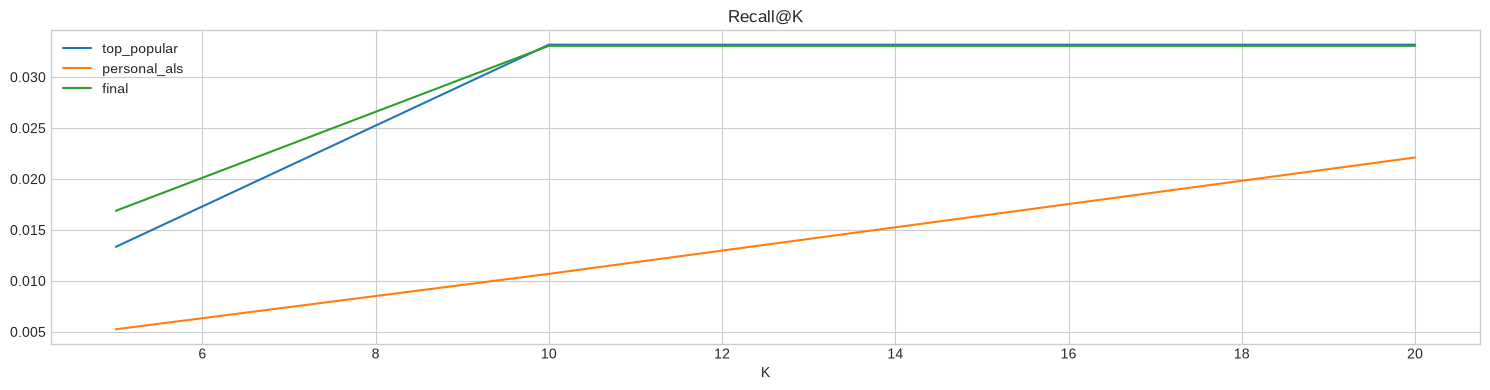

In [215]:
fig, axes = plt.subplots(figsize=(15, 4))

axes.plot([5, 10, 20], [metrics_top_pop[f"recall@{k}"] for k in [5,10,20]], label="top_popular")
axes.plot([5, 10, 20], [metrics_personal[f"recall@{k}"] for k in [5,10,20]], label="personal_als")
axes.plot([5, 10, 20], [metrics_final[f"recall@{k}"] for k in [5,10,20]], label="final")
axes.set_title("Recall@K"); axes.set_xlabel("K"); axes.legend(); axes.grid(True)

plt.tight_layout()
plt.show()

Персональные ALS-рекомендации отстают от топа популярных треков на всех значениях K, что указывает на слабую способность модели улавливать индивидуальные предпочтения пользователей.

Итоговая ранжирующая модель практически повторяет кривую top-popular. Ранжирующая модель в значительной степени опирается на глобальную популярность трека.

#### Precision@K

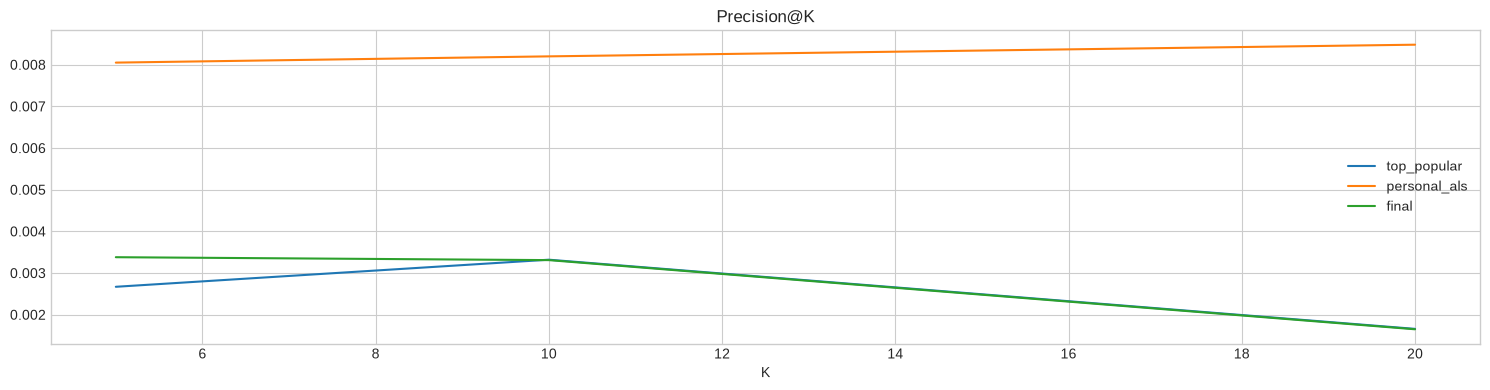

In [216]:
fig, axes = plt.subplots(figsize=(15, 4))

axes.plot([5, 10, 20], [metrics_top_pop[f"precision@{k}"] for k in [5,10,20]], label="top_popular")
axes.plot([5, 10, 20], [metrics_personal[f"precision@{k}"] for k in [5,10,20]], label="personal_als")
axes.plot([5, 10, 20], [metrics_final[f"precision@{k}"] for k in [5,10,20]], label="final")
axes.set_title("Precision@K"); axes.set_xlabel("K"); axes.legend(); axes.grid(True)

plt.tight_layout()
plt.show()

В отличие от `Recall@K` график `Precision@K` показывает, что персональные ALS-рекомендации превосходят топ популярных треков и итоговую модель примерно в 2.5-3 раза. Следовательно, коллаборативная фильтраци способна улавливать индивидуальные предпочтения даже при жестком пороге фильтрации.

График для итоговой модели аналогично с графиком `Recall@K` практически полностью повторяет график для топа треков.

## Заключение

В рамках третьего этапа был успешно реализован полный цикл построения и оценки офлайн-рекомендательной системы, включая решение критической проблемы нехватки оперативной памяти.

**Ключевые результаты:**

* Проблема OOM при работе с 222 млн событий решена за счет агрегации пар (user, track) и строгой cold-start фильтрации (порог 300 прослушиваний), что позволило обучить ALS-модель на матрице ~172k × 95k.
* Сравнение моделей:
  
        ALS (u2i) показал наилучший precision, доказав способность коллаборативной фильтрации улавливать индивидуальные предпочтения лучше, чем глобальный топ.
  
        Итоговый ранжир (Logistic Regression на 3 признаках) обеспечил максимальное покрытие каталога (72.8%), однако его метрики точности и полноты деградировали до уровня базового top-popular.

* Метрика novelty равна 0.0 для всех типов рекомендаций. Это прямое следствие жесткого порога в 300 прослушиваний: модель физически не видит «длинный хвост» каталога и вынуждена рекомендовать только уже относительно популярные композиции.

**Вывод:**

Построенный пайплайн работает корректно и масштабируемо. Однако для требуются доработки для использования в промышленной среде.

# Заключение

В рамках проекта был разработан сквозной пайплайн построения рекомендательной системы для музыкального сервиса: от первичной обработки сырых логов до обучения и оценки гибридных моделей. 

**Основные результаты:**

* Проведена очистка и валидация ~222,6 млн взаимодействий и 1 млн треков. Устранены аномалии (битые ссылки на жанры), данные обогащены метаданными и выгружены в S3. Выявлена сильная правосторонняя асимметрия в активности пользователей и популярности треков.
* Реализованы три подхода: глобальный бейзлайн, персональные рекомендации на основе матричной факторизации (ALS) и финальная ранжирующая модель (Logistic Regression), объединяющая популярность, активность пользователя и ALS-скоры.
* Оценка качества:
  
        ALS доказала свою эффективность: её Precision@K в 2.5–3 раза превосходит глобальный топ, что подтверждает способность модели улавливать индивидуальные вкусы.
  
        Финальная модель обеспечила максимальное покрытие каталога (72.8%) за счет генерации кандидатов из разных источников, однако её ранжирование оказалось сильно смещено в сторону глобальной популярности треков.

**Итог:** 

Создан полноценный рабочий прототип гибридной рекомендательной системы. Для повышения персонализации и новизны рекомендаций в будущем потребуется оптимизация вычислительных ресурсов (или переход на распределенные фреймворки, например, Spark), что позволит снизить пороги cold-start и обучить модели на всем многообразии каталога.